In [19]:
#Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [20]:
#Load CSV file
df = pd.read_csv(r"C:\Users\chand\OneDrive\Desktop\profit analytices\merged_student_dept left join.csv")
print("Dataset Loaded Successfully!")
print(df.shape)

df.head()

Dataset Loaded Successfully!
(50, 5)


,RD_Spend,Administration,Marketing_Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RD_Spend         50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing_Spend  50 non-null     float64
 3   State            50 non-null     object 
 4   Profit           50 non-null     float64
dtypes: float64(4), object(1)
memory usage: 2.1+ KB


In [22]:
print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Rows:", df.duplicated().sum())

Missing Values:
RD_Spend           0
Administration     0
Marketing_Spend    0
State              0
Profit             0
dtype: int64
Duplicate Rows: 0


In [23]:
df.describe()

,RD_Spend,Administration,Marketing_Spend,Profit
count,50.000000,50.000000,50.000000,50.000000
mean,73721.615600,121344.639600,211025.097800,112012.639200
std,45902.256482,28017.802755,122290.310726,40306.180338
min,0.000000,51283.140000,0.000000,14681.400000
25%,39936.370000,103730.875000,129300.132500,90138.902500
50%,73051.080000,122699.795000,212716.240000,107978.190000
75%,101602.800000,144842.180000,299469.085000,139765.977500
max,165349.200000,182645.560000,471784.100000,192261.830000


In [24]:
df["State"].value_counts()

State
New York      17
California    17
Florida       16
Name: count, dtype: int64

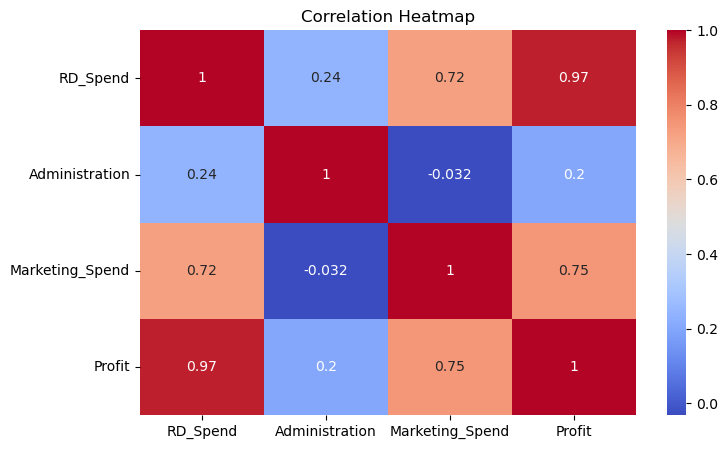

In [25]:
#Correlation heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

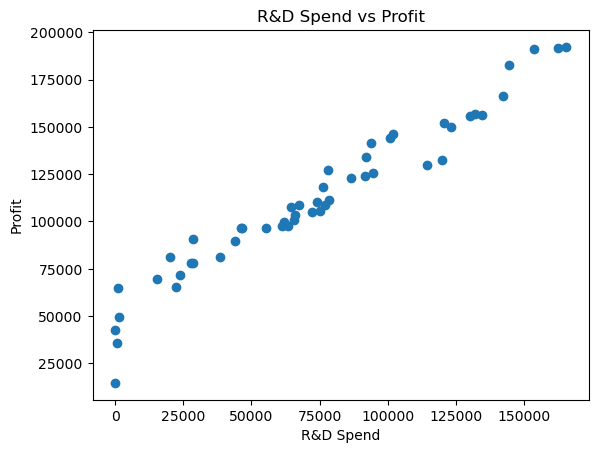

In [26]:
#R&D Spend vs Profit charts
plt.scatter(df["RD_Spend"], df["Profit"])
plt.xlabel("R&D Spend")
plt.ylabel("Profit")
plt.title("R&D Spend vs Profit")
plt.show()


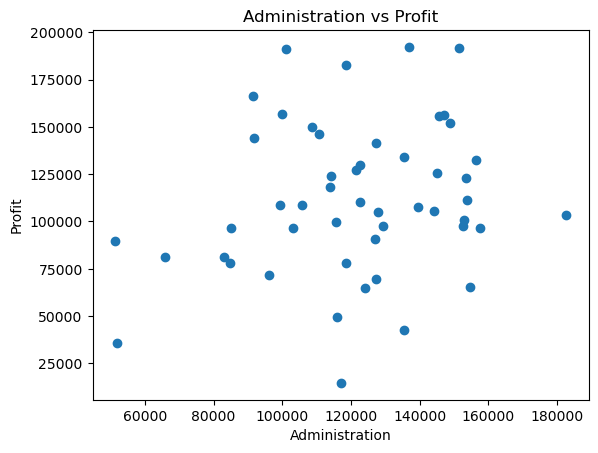

In [27]:
#Administration vs Profit chart
plt.scatter(df["Administration"], df["Profit"])
plt.xlabel("Administration")
plt.ylabel("Profit")
plt.title("Administration vs Profit")
plt.show()

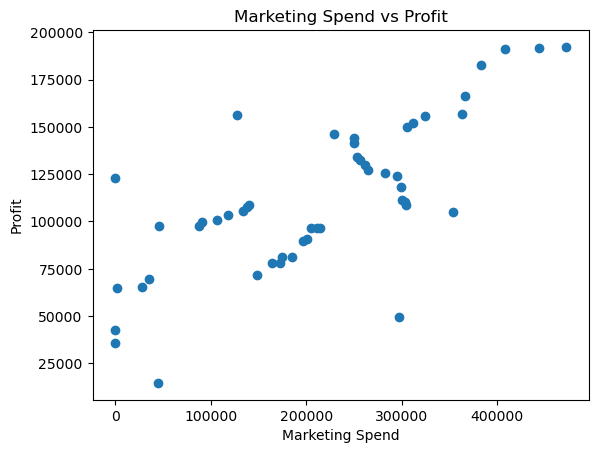

In [28]:
#Marketing Spend vs Profit chart
plt.scatter(df["Marketing_Spend"], df["Profit"])
plt.xlabel("Marketing Spend")
plt.ylabel("Profit")
plt.title("Marketing Spend vs Profit")
plt.show()

In [29]:
#Regression model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

X = df[["RD_Spend", "Administration", "Marketing_Spend"]]
y = df["Profit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R2 Score: 0.9000653083037321
MAE: 6979.152252370399
RMSE: 8995.905803361413


In [30]:
#Predict profit for two companies
new_data = pd.DataFrame({
    "RD_Spend": [21892.92, 23940.93],
    "Administration": [81910.77, 96489.63],
    "Marketing_Spend": [164270.7, 137001.1]
})

final_model = LinearRegression()
final_model.fit(X, y)

predictions = final_model.predict(new_data)

print("Predicted Profit:")

for i, value in enumerate(predictions):
    print("Company", i + 1, ":", round(value, 2))

Predicted Profit:
Company 1 : 70037.9
Company 2 : 70554.57


In [31]:
prediction_table = pd.DataFrame({
    "RD_Spend": [21892.92, 23940.93],
    "Administration": [81910.77, 96489.63],
    "Marketing_Spend": [164270.7, 137001.1],
    "Predicted_Profit": predictions
})

display(prediction_table)

,RD_Spend,Administration,Marketing_Spend,Predicted_Profit
0,21892.92,81910.77,164270.7,70037.904765
1,23940.93,96489.63,137001.1,70554.572560


In [32]:
prediction_table.to_csv(
    "Predicted_Profit_Table.csv",
    index=False
)

In [33]:
df[["RD_Spend", "Marketing_Spend", "Administration", "Profit"]].corr()["Profit"]

RD_Spend           0.972900
Marketing_Spend    0.747766
Administration     0.200717
Profit             1.000000
Name: Profit, dtype: float64

In [34]:
print("Regression Coefficients:")
for name, coef in zip(X.columns, model.coef_):
    print(name, coef)

Regression Coefficients:
RD_Spend 0.8037792756297526
Administration -0.06792917400149993
Marketing_Spend 0.031241545897732773


In [35]:
df[['RD_Spend', 'Administration', 'Marketing_Spend', 'Profit']].corr()

,RD_Spend,Administration,Marketing_Spend,Profit
RD_Spend,1.000000,0.241955,0.724248,0.972900
Administration,0.241955,1.000000,-0.032154,0.200717
Marketing_Spend,0.724248,-0.032154,1.000000,0.747766
Profit,0.972900,0.200717,0.747766,1.000000
